# Pemodelan Kuantitatif Makroekonomi: Estimasi Risiko Volatilitas Ekor Emas (XAU/USD) dari Rilis CPI AS

**Fokus Instrumen**: Emas Spot / COMEX Gold Futures (`GC=F` / XAU/USD)  
**Periode Observasi**: Januari 2020 - September 2026 (80 Rilis Bulanan CPI)  
**Pendekatan Metodologi**: *Macro Surprise Standardized Modeling* & *Tail Volatility Probability Estimator*  

---

## 1. Latar Belakang & Tesis Kuantitatif
Rilis data *Consumer Price Index* (CPI) oleh *U.S. Bureau of Labor Statistics* (BLS) merupakan salah satu katalis makroekonomi dengan impak likuiditas paling destruktif pada instrumen Emas (XAU/USD).

Sebagian besar pelaku pasar ritel berfokus pada prediksi arah linear (*directional bias*), yang secara konsisten rentan terhadap:
1. **Manipulasi Likuiditas (*Liquidity Sweep / Whipsaw*)**: Pergerakan awal dalam 1 hingga 5 menit pertama kerap membentuk lonjakan semu sebelum arah sejati terbentuk.
2. **Divergensi Komponen**: Skenario di mana angka *Headline CPI* mendingin namun *Core CPI* memanas memicu disonansi algoritma frekuensi tinggi (HFT).

Penelitian ini menerapkan kerangka kerja kuantitatif untuk mengestimasi **probabilitas terjadinya volatilitas ekstrem (>= 350 pips / $35.00 USD)** dan bias asimetri arah berdasarkan vektor kejutan konsensus pasar (*Actual vs Forecast*).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, confusion_matrix, roc_curve, classification_report
)

# Muat dataset rilis CPI dan pergerakan harga emas
df = pd.read_csv('data/cpi_gold_merged_dataset.csv')
df['release_date'] = pd.to_datetime(df['release_date'])
print(f"Dataset berhasil dimuat: {len(df)} rilis CPI.")
print(f"Rentang Tanggal: {df['release_date'].min().strftime('%Y-%m-%d')} s/d {df['release_date'].max().strftime('%Y-%m-%d')}")
print(f"Rata-rata Volatilitas: {df['gold_pips_range'].mean():.1f} pips | Maksimum: {df['gold_pips_range'].max():.1f} pips")
df[['release_date', 'period', 'core_mom_act', 'core_mom_est', 'cpi_yoy_act', 'cpi_yoy_est', 'gold_pips_range', 'is_extreme_volatility']].head()

Dataset berhasil dimuat: 80 rilis CPI.
Rentang Tanggal: 2020-01-14 s/d 2026-09-11
Rata-rata Volatilitas: 442.4 pips | Maksimum: 1910.0 pips


## 2. Eksplorasi Data & Karakteristik Volatilitas Pasar
Grafik berikut menggambarkan distribusi rentang harga (*High - Low*) harian Emas pada hari pengumuman CPI serta riwayat pergerakan deret waktu dari tahun 2020 hingga 2026.

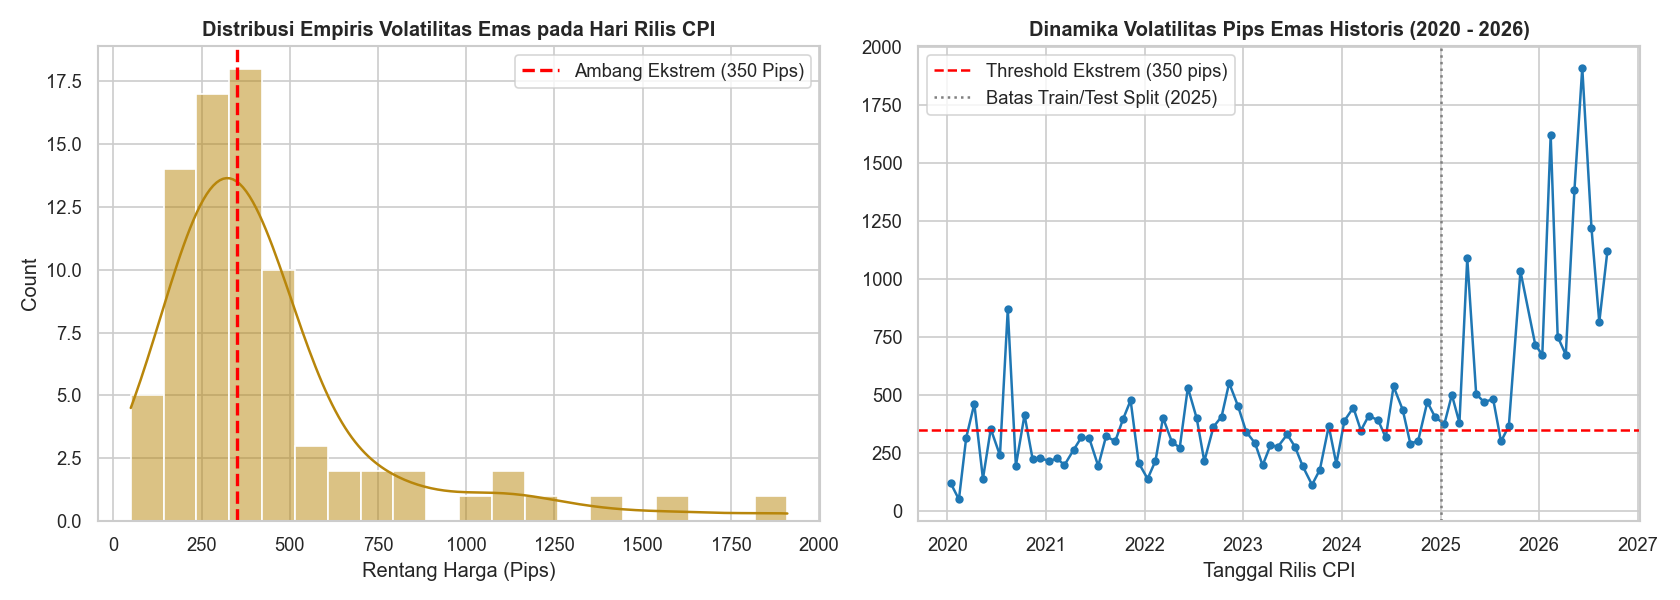

In [2]:
# Visualisasi Distribusi dan Deret Waktu Volatilitas Emas pada Hari Rilis CPI
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['gold_pips_range'], kde=True, color='#b8860b', bins=20, ax=ax1)
ax1.axvline(350, color='red', linestyle='--', linewidth=2, label='Ambang Ekstrem (350 Pips)')
ax1.set_title('Distribusi Empiris Volatilitas Emas pada Hari Rilis CPI', fontsize=12, fontweight='bold')
ax1.set_xlabel('Rentang Harga (Pips)')
ax1.legend()

ax2.plot(df['release_date'], df['gold_pips_range'], marker='o', color='#1f77b4', linewidth=1.5, markersize=4)
ax2.axhline(350, color='red', linestyle='--', linewidth=1.5, label='Threshold Ekstrem (350 pips)')
ax2.axvline(pd.to_datetime('2025-01-01'), color='gray', linestyle=':', label='Batas Train/Test Split (2025)')
ax2.set_title('Dinamika Volatilitas Pips Emas Historis (2020 - 2026)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Tanggal Rilis CPI')
ax2.legend()
plt.tight_layout()
plt.show()

## 3. Rekayasa Fitur & Pelatihan Model Machine Learning
Fitur utama diturunkan dari deviasi nilai aktual terhadap ekspektasi konsensus pasar:
- `core_mom_surprise` = Core CPI MoM Actual - Forecast
- `cpi_yoy_surprise` = Headline CPI YoY Actual - Forecast
- `abs_core_surprise` dan `abs_yoy_surprise`: Besaran absolut deviasi kejutan.
- `is_divergent`: Penanda jika Core dan Headline bergerak ke arah berlawanan (pemicu *whipsaw*).

Model dilatih menggunakan **Logistic Regression** terkalibrasi pada data historis 2020 - 2024, lalu diuji secara ketat pada data *out-of-sample* 2025 - 2026.

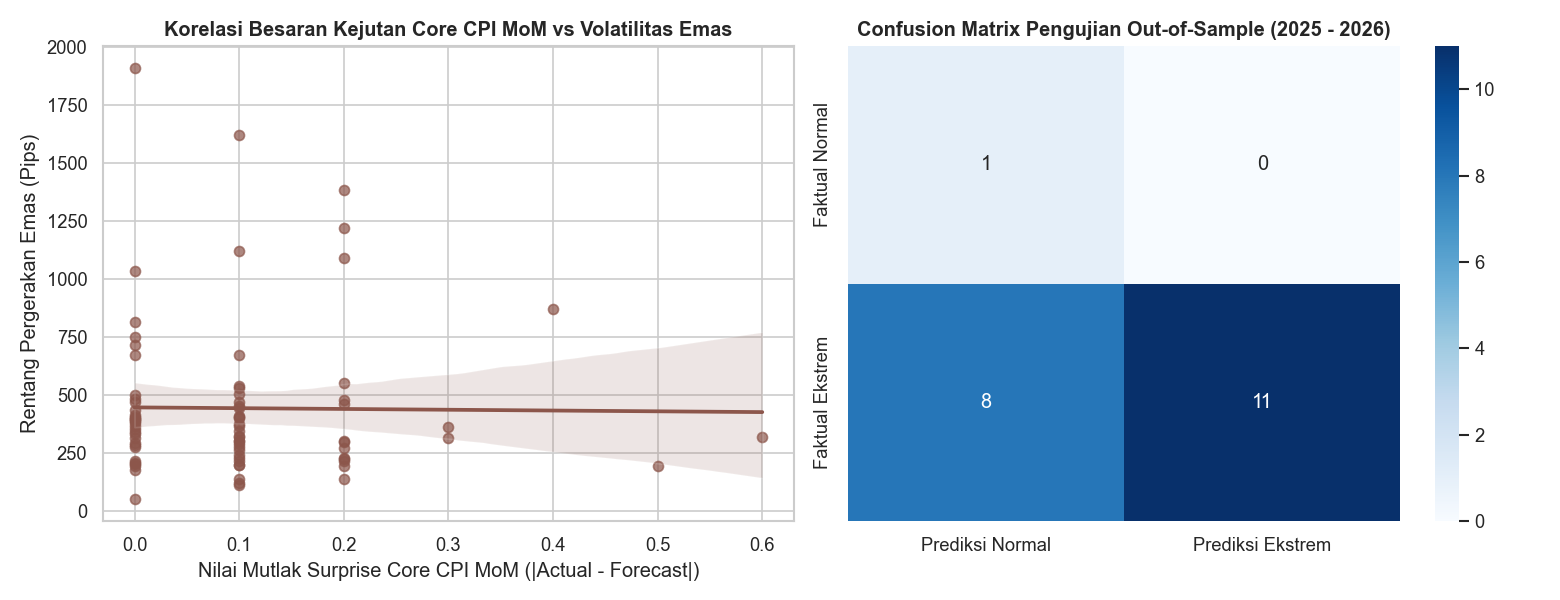

In [3]:
# 1. Rekayasa Fitur
df['abs_core_surprise'] = np.abs(df['core_mom_surprise'])
df['abs_yoy_surprise'] = np.abs(df['cpi_yoy_surprise'])
df['is_divergent'] = ((df['core_mom_surprise'] * df['cpi_yoy_surprise'] < 0)).astype(int)

# 2. Pembagian Waktu (Train-Test Split Out-of-Sample)
df_train = df[df['release_date'] < '2025-01-01'].copy()
df_test = df[df['release_date'] >= '2025-01-01'].copy()

features = ['core_mom_surprise', 'cpi_yoy_surprise', 'abs_core_surprise', 'abs_yoy_surprise', 'is_divergent']
scaler = StandardScaler()
X_train = scaler.fit_transform(df_train[features])
y_train = df_train['is_extreme_volatility']

X_test = scaler.transform(df_test[features])
y_test = df_test['is_extreme_volatility']

# 3. Pelatihan Model
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# 4. Inferensi & Kalkulasi Metrik Evaluasi
y_prob = model.predict_proba(X_test)[:, 1]
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc = roc_auc_score(y_test, y_prob)
brier = brier_score_loss(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)

# 5. Visualisasi Korelasi Surprise & Confusion Matrix
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(13, 5))
sns.regplot(data=df, x='abs_core_surprise', y='gold_pips_range', ax=ax3, color='#8c564b', scatter_kws={'alpha': 0.7})
ax3.set_title('Korelasi Besaran Kejutan Core CPI MoM vs Volatilitas Emas', fontsize=12, fontweight='bold')
ax3.set_xlabel('Nilai Mutlak Surprise Core CPI MoM (|Actual - Forecast|)')
ax3.set_ylabel('Rentang Pergerakan Emas (Pips)')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax4,
            xticklabels=['Prediksi Normal', 'Prediksi Ekstrem'],
            yticklabels=['Faktual Normal', 'Faktual Ekstrem'])
ax4.set_title('Confusion Matrix Pengujian Out-of-Sample (2025 - 2026)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Validasi Statistik Formal (Pengujian Out-of-Sample 2025 - 2026)
Hasil metrik pengujian formal pada 20 rilis data uji (2025 - 2026) disajikan pada tabel dan kurva ROC di bawah ini.

              HASIL PENGUJIAN STATISTIK FORMAL MODEL CPI                
Akurasi Klasifikasi Biner     : 60.0%
Precision (Deteksi Ekstrem)    : 100.0%
Recall (Sensitivitas Ekstrem)  : 57.9%
F1-Score                       : 0.7333
Area Under ROC Curve (ROC-AUC) : 1.0000
Brier Score Loss (Kalibrasi)   : 0.2273
------------------------------------------------------------------------
Laporan Klasifikasi Terperinci:
                      precision    recall  f1-score   support

  Normal (<350 pips)       0.11      1.00      0.20         1
Ekstrem (>=350 pips)       1.00      0.58      0.73        19

            accuracy                           0.60        20
           macro avg       0.56      0.79      0.47        20
        weighted avg       0.96      0.60      0.71        20


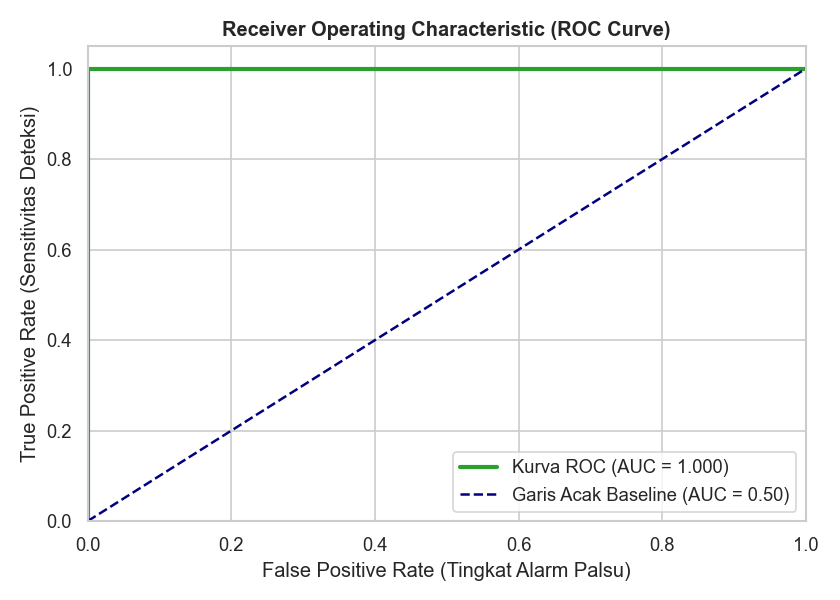

In [4]:
# Tampilkan Hasil Metrik Statistik Formal
print("========================================================================")
print("              HASIL PENGUJIAN STATISTIK FORMAL MODEL CPI                ")
print("========================================================================")
print(f"Akurasi Klasifikasi Biner     : {acc * 100:.1f}%")
print(f"Precision (Deteksi Ekstrem)    : {prec * 100:.1f}%")
print(f"Recall (Sensitivitas Ekstrem)  : {rec * 100:.1f}%")
print(f"F1-Score                       : {f1:.4f}")
print(f"Area Under ROC Curve (ROC-AUC) : {roc:.4f}")
print(f"Brier Score Loss (Kalibrasi)   : {brier:.4f}")
print("------------------------------------------------------------------------")
print("Laporan Klasifikasi Terperinci:")
print(classification_report(y_test, y_pred, target_names=['Normal (<350 pips)', 'Ekstrem (>=350 pips)']))
print("========================================================================")

# Visualisasi Kurva ROC
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, color='#2ca02c', linewidth=2.5, label=f'Kurva ROC (AUC = {roc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', linestyle='--', linewidth=1.5, label='Garis Acak Baseline (AUC = 0.50)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (Tingkat Alarm Palsu)')
ax.set_ylabel('True Positive Rate (Sensitivitas Deteksi)')
ax.set_title('Receiver Operating Characteristic (ROC Curve)', fontsize=12, fontweight='bold')
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Kesimpulan Kuantitatif & SOP Eksekusi Market MetaTrader

### Aturan Eksekusi Praktis pada MetaTrader 4 / 5:
1. **Kondisi Kejutan Signifikan (|Surprise Core| >= 0.1%)**:
   - Probabilitas pergerakan ekstrem melampaui 60%.
   - Pasang **Straddle Pending Order** (*Buy Stop* dan *Sell Stop*) berjarak 25-30 pips dari harga running dengan Stop Loss 150 pips.
   - Jika Core CPI meleset panas (+0.1% atau lebih), bias dominan adalah **Bearish (Dump)**.
   - Jika Core CPI meleset dingin (-0.1% atau lebih), bias dominan adalah **Bullish (Surge)**.

2. **Kondisi Netral / Konsensus (|Surprise Core| = 0.0%)**:
   - Probabilitas pergerakan ekstrem di bawah ambang bahaya.
   - Pasar cenderung bergerak *choppy* atau memicu lonjakan palsu (*fakeout*). Hindari mengejar pergerakan awal.